# 01 — Tabular Q-Learning on CartPole-v1

Training is run reproducibly from the command line (`python -m scripts.run_all`); this notebook **inspects** the discretizer and **analyses** the saved logs. Set `RUN_DEMO = True` to train a short demo agent inline.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS = ROOT / "results"

## 1. The discretizer
Interior edges per dimension, the state count, and the sign split at 0.

In [2]:
import yaml
from src.environments.discretizer import UniformDiscretizer
cfg = yaml.safe_load((ROOT / "configs" / "cartpole.yaml").read_text())
r = cfg["tabular"]["ranges"]["primary"]
for bins in cfg["tabular"]["bins"]:
    d = UniformDiscretizer(r["low"], r["high"], bins)
    print(f"{bins:>2} bins -> {d.n_states:>7,} states, Q-table {d.n_states*2*8/1024:8.1f} KiB")
d6 = UniformDiscretizer(r["low"], r["high"], 6)
for name, e in zip(["x", "x_dot", "theta", "theta_dot"], d6.edges):
    print(f"{name:>9}: interior edges {np.round(e, 4)}")
print("bin indices of (-1e-6,...) vs (+1e-6,...):", d6.bin_indices(np.full(4, -1e-6)), d6.bin_indices(np.full(4, 1e-6)))

 6 bins ->   1,296 states, Q-table     20.2 KiB
10 bins ->  10,000 states, Q-table    156.2 KiB
20 bins -> 160,000 states, Q-table   2500.0 KiB
        x: interior edges [-1.6 -0.8  0.   0.8  1.6]
    x_dot: interior edges [-1.3333 -0.6667  0.      0.6667  1.3333]
    theta: interior edges [-0.1397 -0.0698  0.      0.0698  0.1397]
theta_dot: interior edges [-2. -1.  0.  1.  2.]
bin indices of (-1e-6,...) vs (+1e-6,...): [2 2 2 2] [3 3 3 3]


## 2. Optional short demo run (not part of the reported results)

In [3]:
RUN_DEMO = False
if RUN_DEMO:
    from scripts.train import build_and_train, load_config
    demo_cfg = load_config(ROOT / "configs" / "cartpole.yaml", ["training.total_steps=20000"])
    build_and_train("tabular", 999, demo_cfg, bins=10, results_root=ROOT / "results" / "demo")

## 3. Results across seeds 0–4

In [4]:
per_run = pd.read_csv(RESULTS / "comparison" / "per_run_metrics.csv")
tab = per_run[per_run.run_name.str.startswith("tabular")]
cols = ["run_name", "seed", "final_eval_mean_100", "steps_to_threshold", "best_checkpoint_mean_10",
        "mean_eval_over_training", "train_time_s", "diag_fraction_states_visited", "diag_median_visits_per_visited_state",
        "diag_out_of_range_fraction_dim1", "diag_out_of_range_fraction_dim3"]
tab[cols]

,run_name,seed,final_eval_mean_100,steps_to_threshold,best_checkpoint_mean_10,mean_eval_over_training,train_time_s,diag_fraction_states_visited,diag_median_visits_per_visited_state,diag_out_of_range_fraction_dim1,diag_out_of_range_fraction_dim3
5,tabular_b6_primary,0,188.680,NaN,354.200,211.476,14.314,0.281,36.000,0.015,0.000
6,tabular_b6_primary,1,200.970,NaN,382.100,169.888,14.521,0.315,32.000,0.006,0.000
7,tabular_b6_primary,2,186.340,NaN,331.200,171.176,14.326,0.336,23.500,0.009,0.000
8,tabular_b6_primary,3,251.500,NaN,317.900,187.178,14.158,0.320,35.000,0.011,0.000
9,tabular_b6_primary,4,240.430,NaN,324.900,194.429,15.116,0.325,21.000,0.010,0.000
10,tabular_b10_primary,0,354.720,NaN,459.500,248.924,14.240,0.130,6.000,0.001,0.000
11,tabular_b10_primary,1,491.330,145000.000,500.000,266.649,14.205,0.103,7.000,0.002,0.000
12,tabular_b10_primary,2,139.840,NaN,319.400,170.544,15.342,0.139,8.000,0.006,0.000
13,tabular_b10_primary,3,371.630,160000.000,483.800,266.798,14.781,0.139,6.000,0.002,0.000
14,tabular_b10_primary,4,430.610,195000.000,499.100,246.439,14.631,0.148,5.000,0.006,0.000


In [5]:
summary = pd.read_csv(RESULTS / "comparison" / "summary.csv").set_index("run_name")
summary.loc[[n for n in summary.index if n.startswith("tabular")]].T

run_name,tabular_b6_primary,tabular_b10_primary,tabular_b20_primary,tabular_b10_tight,tabular_b6_primary_eps50k,tabular_b10_primary_eps50k,tabular_b20_primary_eps50k,tabular_b10_tight_eps50k
n_seeds,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000
final_mean,213.584,357.626,290.536,317.778,203.140,179.984,158.394,250.690
final_ci95_half_width,37.655,165.211,77.837,68.119,70.743,68.026,62.449,147.689
final_std_across_seeds,30.331,133.078,62.697,54.870,56.983,54.795,50.303,118.963
final_min,186.340,139.840,206.480,259.810,144.660,87.250,109.120,91.330
final_max,251.500,491.330,377.770,389.580,272.660,222.640,212.010,410.980
seeds_final_success,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
seeds_reaching_threshold_ever,0.000,3.000,0.000,2.000,0.000,0.000,0.000,1.000
median_steps_to_threshold,NaN,160000.000,NaN,145000.000,NaN,NaN,NaN,180000.000
seeds_sustained_threshold,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000


## 4. Effect of granularity and of the velocity ranges

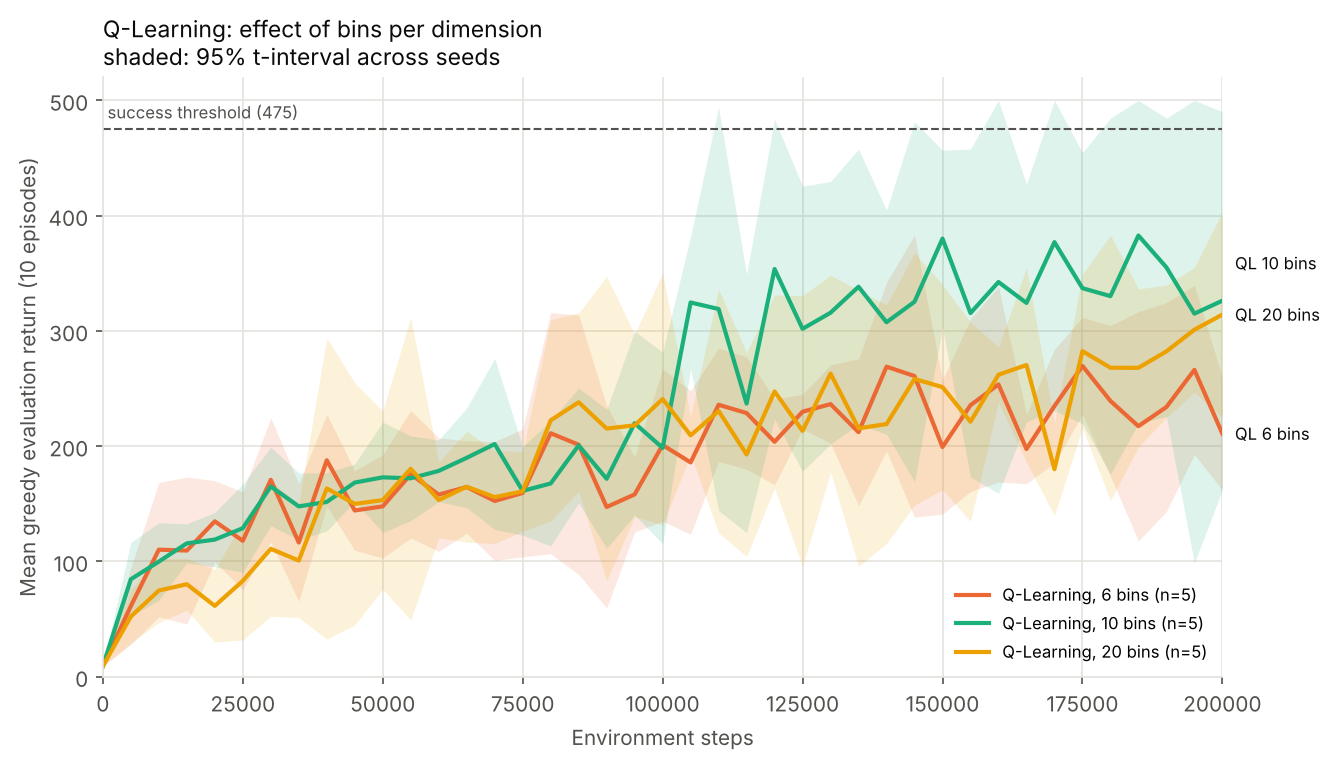

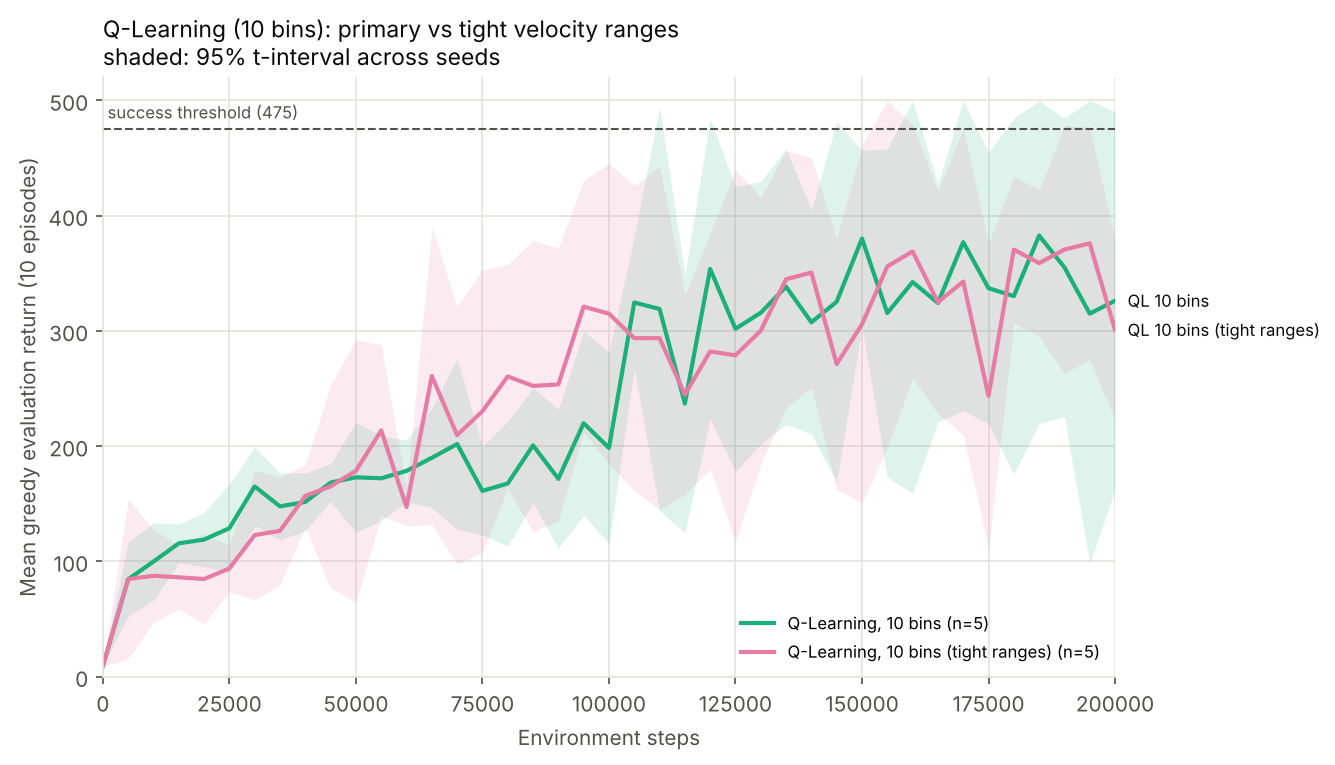

In [6]:
display(Image(RESULTS / "tabular" / "figures" / "granularity_ci95.png"))
display(Image(RESULTS / "tabular" / "figures" / "range_ablation_ci95.png"))

## 5. Where does the 10-bin agent spend its time?
Visit counts per (θ bin, θ̇ bin), summed over x and ẋ, for seed 0. This shows how concentrated the visited part of the table is.

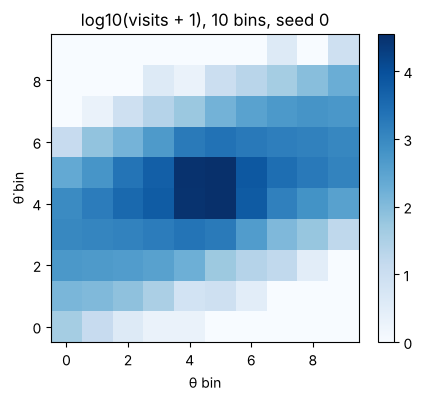

fraction of all visits in the 4 central θ̇ bins: 0.975235


In [7]:
m = np.load(RESULTS / "tabular" / "models" / "tabular_b10_primary" / "seed_0.npz")
visits = m["visit_counts"].reshape(tuple(m["bins"]))
theta_thetadot = visits.sum(axis=(0, 1))
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(np.log10(theta_thetadot + 1).T, origin="lower", cmap="Blues")
ax.set_xlabel("θ bin"); ax.set_ylabel("θ̇ bin"); ax.set_title("log10(visits + 1), 10 bins, seed 0")
fig.colorbar(im, ax=ax); plt.show()
print("fraction of all visits in the 4 central θ̇ bins:", theta_thetadot[:, 3:7].sum() / theta_thetadot.sum())